# Does Speculative Crowding Improve Commodity ETF Strategies?

*Hafsa El Ibrahimi and Mohamed Guendzi*

**Context.** Factor strategies such as momentum have earned less in recent years than in their historical backtests. Kang, Rouwenhorst and Tang (2021) relate part of this decline to crowding: using the positions of speculators published each week by the CFTC, they show that commodity factor returns accrue mainly when speculators are not already crowded into the trade. However, two important questions remain. First, the original paper uses CFTC positions recorded on Tuesdays, although these positions are only published on Fridays, making the proposed timing difficult to implement in practice. This raises the question of whether the crowding effect persists when accounting for the actual availability of information. Second, while the paper focuses on traditional commodity factors, it remains unclear whether crowding signals can also improve machine-learning-based strategies. We investigate these questions by assessing the incremental value of crowding information for both classical momentum and machine-learning strategies.

**Contribution.** (i) We replace the paper's commercial futures prices with 12 investable commodity ETFs, downloaded in the notebook. (ii) Our sample runs to 2026, after the end of the paper's sample in 2019. (iii) We measure what the paper's timing is worth by using only published positions. (iv) We apply the indicator to two machine-learning strategies, Ridge and XGBoost, which forecast each ETF's next-week return, and we report their returns after transaction costs.

**Main results.** With the paper's timing, the low-crowding momentum strategy has a Sharpe ratio of 0.38, against 0.25 for classical momentum. Using only published positions, it falls to 0.25: the effect relies on positions that are not yet public at the time of the decision. On the machine-learning strategies, with the same timing as in Part 1 and before costs, the indicator brings no significant improvement over 2019-2026: the alpha of the filtered strategy over the unfiltered one has a t-statistic of -0.85 for Ridge and 0.25 for XGBoost. Neither model beats classical momentum, and both lose money after costs.

**References.** Kang, Rouwenhorst and Tang (2021), *Crowding and Factor Returns*, SSRN 3814952. Chen and Guestrin (2016), *XGBoost: A Scalable Tree Boosting System*. Newey and West (1987), *A Simple, Positive Semi-Definite, Heteroskedasticity and Autocorrelation Consistent Covariance Matrix*. Code: the course package [`skfin`](https://github.com/schampon/skfin) (backtesting, metrics, plots and data loading), scikit-learn, XGBoost and statsmodels. Data: [CFTC Commitments of Traders](https://publicreporting.cftc.gov/Commitments-of-Traders/Legacy-Futures-Only/6dca-aqww), Yahoo Finance and [FRED](https://fred.stlouisfed.org).

In [1]:
%%capture
# XGBoost is not in the course environment
%pip install xgboost==3.4.1

In [2]:
from urllib.parse import urlencode

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from skfin.backtesting import compute_pnl
from skfin.backtesting_with_cost import average_holding_period
from skfin.dataloaders.cache import CacheManager
from skfin.dataloaders.web_utils import WebUtils
from skfin.datasets import load_yf_returns
from skfin.metrics import drawdown, sharpe_ratio
from skfin.plot import line

START, END = "2010-01-01", "2026-11-01"
CACHE = "data"
N_LEG = 6

# ETF ticker -> CFTC code of the corresponding futures market
MARKETS = {
    "USO": "067651",  # WTI crude oil
    "UNG": "023651",  # natural gas
    "UGA": "111659",  # RBOB gasoline
    "CPER": "085692",  # copper
    "CORN": "002602",  # corn
    "WEAT": "001602",  # wheat
    "SOYB": "005602",  # soybeans
    "CANE": "080732",  # sugar
    "GLD": "088691",  # gold
    "SLV": "084691",  # silver
    "PPLT": "076651",  # platinum
    "PALL": "075651",  # palladium
}

sr = lambda x: sharpe_ratio(x, 52, remove_zeros=False)

## 1. Data

**Returns.** The paper uses nearby futures prices from Commodity Systems Inc., which are not free. We use ETFs instead. Eight hold futures and roll them (USO, UNG, UGA, CPER, CORN, WEAT, SOYB, CANE); four hold the metal (GLD, SLV, PPLT, PALL). ETF returns therefore approximate rolled futures returns, net of fees and with each fund's own roll schedule. We use adjusted prices and compound daily returns from Tuesday to Tuesday to obtain the weekly return of ETF $i$:

$$
r_{i,t} = \prod_{d \in \text{week } t} \left(1 + r^{day}_{i,d}\right) - 1.
$$


**Positions.** The CFTC Legacy, futures-only report gives, each week, the long and short positions of non-commercial traders and the open interest $OI_{i,t}$ of each market. Following equations (2)-(4) of the paper, speculative pressure and crowding are:

$$
Q_{i,t} = \frac{Long_{i,t} - Short_{i,t}}{OI_{i,t}},
\qquad
C_{i,t} = Q_{i,t} - \frac{1}{52}\sum_{k=1}^{52} Q_{i,t-k}.
$$

In [3]:
daily = load_yf_returns(list(MARKETS), start=START, end=END, cache_dir=CACHE)["price_returns"]
ret = daily.add(1).resample("W-TUE").prod(min_count=1).sub(1).loc[:END, list(MARKETS)]


def load_crowding(dataset="6dca-aqww"):
    def download():
        query = {
            "$select": "report_date_as_yyyy_mm_dd as report, cftc_contract_market_code as code, "
            "open_interest_all as oi, noncomm_positions_long_all as l, noncomm_positions_short_all as s",
            "$where": f"cftc_contract_market_code in {tuple(MARKETS.values())} "
            f"and report_date_as_yyyy_mm_dd between '{START}' and '{END}'",
            "$limit": 100000,
        }
        url = f"https://publicreporting.cftc.gov/resource/{dataset}.json?{urlencode(query)}"
        return pd.DataFrame(WebUtils.get_response(url).json())

    raw = CacheManager(CACHE).get_cached_dataframe(f"cot_{dataset}.parquet", download)
    raw = raw.astype({"oi": float, "l": float, "s": float}).assign(report=lambda x: pd.to_datetime(x["report"]))
    q = raw.assign(q=(raw["l"] - raw["s"]) / raw["oi"]).pivot(index="report", columns="code", values="q")
    q = q.rename(columns={v: k for k, v in MARKETS.items()})[list(MARKETS)]
    return q - q.shift(1).rolling(52).mean()


crowding = load_crowding()
pd.DataFrame(
    {
        "first return": ret.apply(lambda x: x.first_valid_index().date()),
        "return (%/yr)": ret.mean() * 5200,
        "vol (%/yr)": ret.std() * np.sqrt(52) * 100,
        "crowding mean": crowding.mean(),
        "crowding std": crowding.std(),
    }
).round(2)

,first return,return (%/yr),vol (%/yr),crowding mean,crowding std
USO,2010-01-05,3.07,36.95,-0.00,0.04
UNG,2010-01-05,-17.97,47.57,0.00,0.05
UGA,2010-01-05,14.25,35.08,-0.00,0.04
CPER,2011-11-22,5.57,22.07,0.00,0.10
CORN,2010-06-15,-0.15,20.42,-0.00,0.11
WEAT,2011-09-20,-8.05,25.35,-0.00,0.08
SOYB,2011-09-20,1.87,16.91,-0.00,0.11
CANE,2011-09-20,-2.64,22.34,-0.01,0.10
GLD,2010-01-05,8.56,16.22,0.00,0.11
SLV,2010-01-05,11.18,31.39,-0.00,0.10


Returns differ widely across funds: UNG loses about 18% a year while UGA gains about 14%. Crowding measures the deviation of speculative positions from their past average, so its mean stays close to zero; its standard deviation ranges from 0.04 (USO, UGA) to 0.16 (PALL).

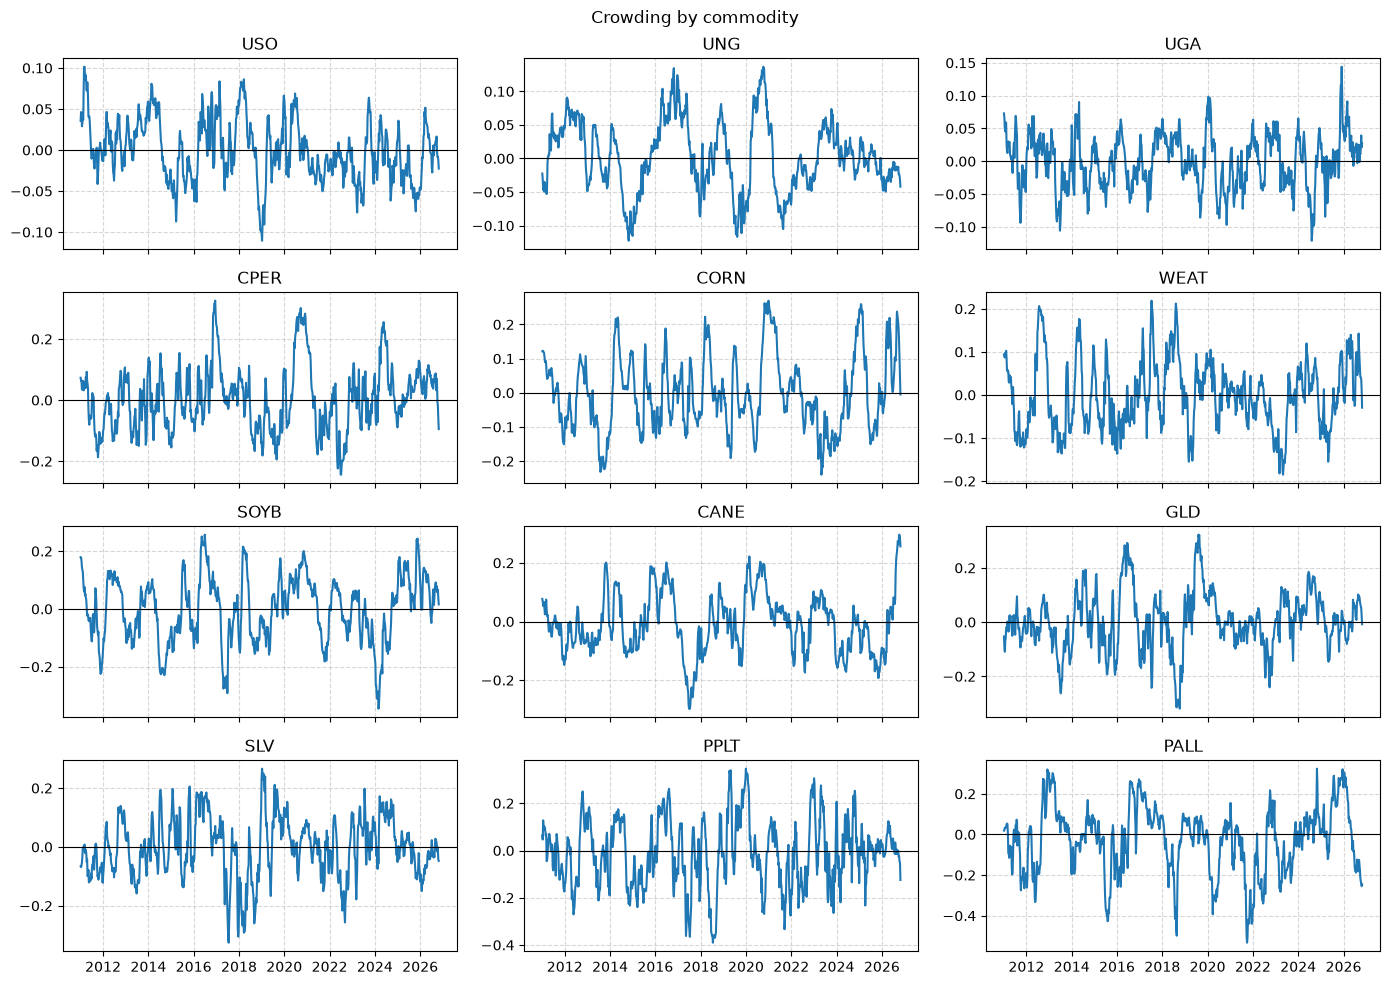

In [4]:
fig, axes = plt.subplots(4, 3, figsize=(14, 10), sharex=True)
for ax, ticker in zip(axes.flat, MARKETS):
    line(crowding[ticker], ax=ax, title=ticker, legend=False, sort=False)
    ax.axhline(0, color="black", lw=0.8)
fig.suptitle("Crowding by commodity")
fig.tight_layout()

## 2. Method

**Momentum.** Each Tuesday we rank the 12 ETFs on their past 52-week return, buy the top 6 and short the bottom 6 with equal weights, and hold for one week (the paper trades 13 against 13):

$$
MOM_{i,t} = \prod_{k=0}^{51}(1 + r_{i,t-k}) - 1,
\qquad
w_{i,t} = \begin{cases} +1/6 & \text{if } i \in L_t \text{ (top 6)} \\ -1/6 & \text{if } i \in S_t \text{ (bottom 6)} \end{cases}
\qquad
R^{MOM}_{t+1} = \sum_{i=1}^{12} w_{i,t}\, r_{i,t+1}.
$$

**Factor crowding.** Following equation (5) of the paper, we average the crowding of the constituents, with a plus sign for longs and a minus sign for shorts:

$$
C^{MOM}_t = \frac{1}{2}\left(\frac{1}{6}\sum_{i \in L_t} C_{i,t} - \frac{1}{6}\sum_{i \in S_t} C_{i,t}\right) = \frac{1}{2}\sum_{i=1}^{12} w_{i,t}\, C_{i,t}.
$$

**Crowding rule.** As in Figure 2 of the paper, the low-crowding strategy holds the momentum portfolio only when factor crowding is below its average over the previous 156 weeks, and stays in cash otherwise. The high-crowding strategy does the opposite, so the two add up to classical momentum:

$$
\bar C_t = \frac{1}{156}\sum_{k=1}^{156} C^{MOM}_{t-k},
\qquad
e_t = \mathbb{1}_{\{C^{MOM}_t < \bar C_t\}},
$$

$$
R^{LOW}_{t+1} = e_t\, R^{MOM}_{t+1},
\qquad
R^{HIGH}_{t+1} = (1 - e_t)\, R^{MOM}_{t+1}.
$$

**Scope.** As in the paper, we ask whether crowding predicts momentum returns, not whether a fund could trade on it. Positions are dated on the Tuesday they are measured, $C_{i,t}$, before the return of the following week, but the CFTC only publishes them on the Friday. Returns are before transaction costs; Section 4 also reports net returns. Our results are therefore descriptive, not an executable backtest.

Sharpe ratios are annualised with $\sqrt{52}$, and cumulative returns are sums of weekly returns, as in the course.

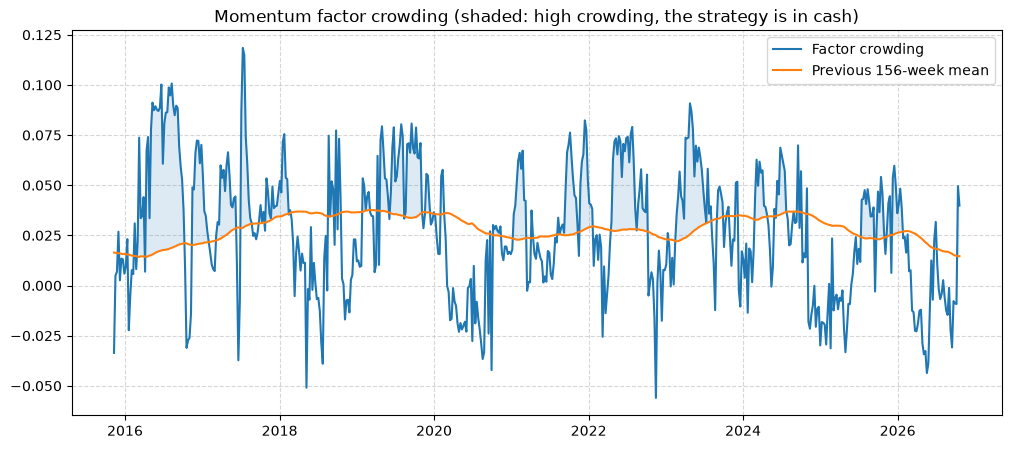

In [5]:
mom = np.log1p(ret).rolling(52).sum().dropna().iloc[:-1]  # same ranking as the 52-week return; the last week has no next-week return
rank = mom.rank(axis=1, ascending=False, method="first")
w = (rank.le(N_LEG).astype(float) - rank.gt(N_LEG).astype(float)) / N_LEG


def factor_crowding(crowding, lag=0, weights=None):
    weights = w if weights is None else weights
    aligned = crowding.reindex(ret.index, method="ffill", tolerance=pd.Timedelta(days=6)).shift(lag)
    return 0.5 * (weights * aligned.loc[weights.index]).sum(axis=1)


def regime(crowding, lag=0, window=156, weights=None):
    C = factor_crowding(crowding, lag, weights)
    threshold = C.shift(1).rolling(window).mean().dropna()
    return C.loc[threshold.index], threshold, C.loc[threshold.index] < threshold


def book(crowding, lag=0):
    _, _, low = regime(crowding, lag)
    h = w.loc[low.index]
    return {
        "Classical": h,
        "Low crowding": h.mul(low.astype(float), axis=0),
        "High crowding": h.mul((~low).astype(float), axis=0),
    }


def pnl(h):
    return compute_pnl(h.reindex(ret.index), ret, 1).reindex(h.index + pd.Timedelta(weeks=1))


def report(strategies):
    return pd.DataFrame(
        {
            name: {
                "Sharpe": sr(pnl(h)),
                "return (%/yr)": pnl(h).mean() * 5200,
                "vol (%/yr)": pnl(h).std() * np.sqrt(52) * 100,
                "max drawdown (%)": drawdown(pnl(h), return_in_risk_unit=False).min() * 100,
                "weeks invested (%)": h.abs().sum(axis=1).gt(0).mean() * 100,
                "holding period (weeks)": average_holding_period(h),
            }
            for name, h in strategies.items()
        }
    ).T.round(2)


C, threshold, low = regime(crowding)
fig, ax = plt.subplots(figsize=(12, 5))
line(
    pd.DataFrame({"Factor crowding": C, "Previous 156-week mean": threshold}),
    ax=ax, sort=False, loc="best", title="Momentum factor crowding (shaded: high crowding, the strategy is in cash)",
)
ax.fill_between(C.index, C, threshold, where=~low, alpha=0.15);

## 3. Results

### Performance

In [6]:
report(book(crowding))

,Sharpe,return (%/yr),vol (%/yr),max drawdown (%),weeks invested (%),holding period (weeks)
Classical,0.25,5.06,20.52,-37.64,100.00,14.48
Low crowding,0.38,5.81,15.25,-25.58,50.87,4.62
High crowding,-0.05,-0.75,13.73,-58.57,49.13,4.62


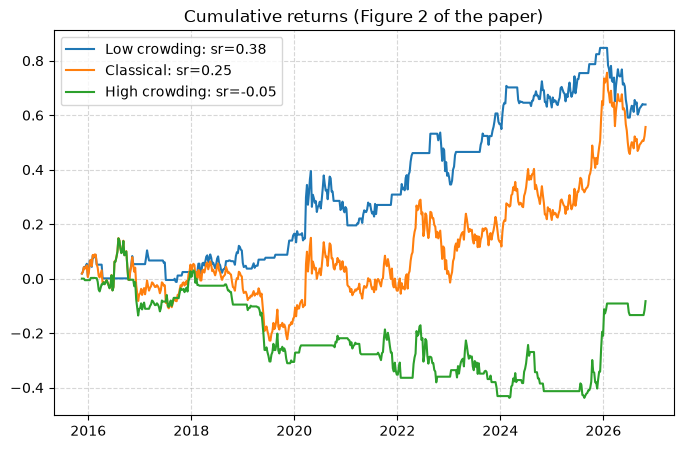

In [7]:
pnls = {k: pnl(h) for k, h in book(crowding).items()}
line({f"{k}: sr={sr(v):.2f}": v for k, v in pnls.items()}, cumsum=True, legend_sharpe_ratio=False, loc="best", title="Cumulative returns (Figure 2 of the paper)")

Classical momentum split by crowding regime (in % of return):

In [8]:
(pnl(w.loc[low.index]) * 100).groupby(np.where(low, "Low crowding", "High crowding")).agg(
    weeks="size", mean_weekly="mean", total="sum"
).round(3)

,weeks,mean_weekly,total
High crowding,281,-0.029,-8.259
Low crowding,291,0.220,63.930


### Can this be executed?

The results above follow the timing of the paper: the decision taken on Tuesday $t$ uses the positions measured on that same Tuesday, $C_{i,t}$. The paper describes the report as published on Tuesday (its Section 2). In practice, the CFTC measures positions at the close on Tuesday and releases them on Friday at 15:30 New York time. Investors therefore do not know $C_{i,t}$ on the day of the decision, and Figure 2 cannot be executed as such: it shows a link between crowding and subsequent returns, not a tradable rule.

We measure what this timing is worth by replacing $C_{i,t}$ with the latest report that is public on Tuesday $t$, the one measured a week earlier (lag 1):

$$
C^{MOM}_t = \frac{1}{2}\sum_{i=1}^{12} w_{i,t}\, C_{i,t-1}.
$$

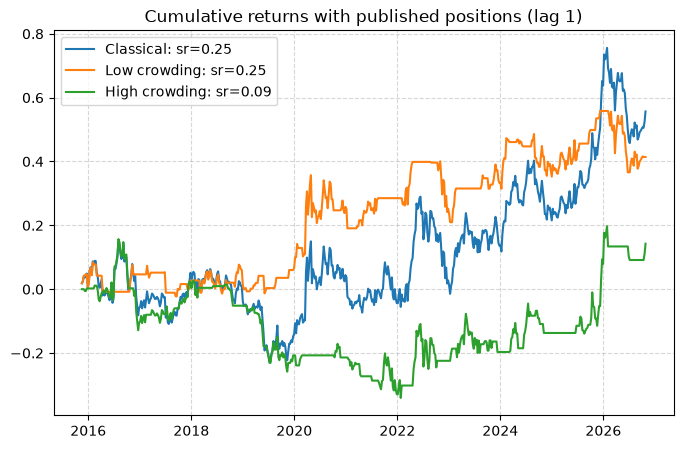

In [9]:
line({f"{k}: sr={sr(pnl(h)):.2f}": pnl(h) for k, h in book(crowding, lag=1).items()}, cumsum=True, legend_sharpe_ratio=False, loc="best", title="Cumulative returns with published positions (lag 1)")

### Reading of the results

- **Same shape as the paper.** With the paper's timing, momentum earns more after low crowding than after high crowding: 64% against -8% in cumulative returns.
- **Not executable as such.** With published positions, the gap narrows to 41% against 14%, and the low-crowding strategy has a Sharpe ratio of 0.25, the same as classical momentum. The paper documents a link between crowding and subsequent momentum returns, but with these data this link does not give an investor a better strategy than simple momentum.

## 4. Machine learning

We now let a model choose the portfolio. Each Tuesday, Ridge and XGBoost predict next week's return of each ETF, without crowding, and we buy the six highest forecasts and sell the other six, as in Section 2. We follow Chapters 4 and 7 of the course: `skfin.Backtester` with a 156-week rolling training window, weekly refitting, and `ParameterSampler` to choose the hyperparameters on the early years only. Section 4.6 then adds the crowding indicator.

In [10]:
from io import StringIO

import yfinance as yf
from pathlib import Path
import hashlib

import statsmodels.api as sm
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import ParameterSampler
from sklearn.base import BaseEstimator
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor
from skfin.backtesting import Backtester
from skfin.estimators import Ridge

TRAIN_WEEKS = 156
COST_BPS = 5
ETFS = list(MARKETS)

GROUPS = {
    "USO": "Energy", "UNG": "Energy", "UGA": "Energy",
    "CPER": "Industrial metal",
    "CORN": "Agriculture", "WEAT": "Agriculture",
    "SOYB": "Agriculture", "CANE": "Agriculture",
    "GLD": "Precious metal", "SLV": "Precious metal",
    "PPLT": "Precious metal", "PALL": "Precious metal",
}


def load_extra_data():
    def yahoo():
        raw = yf.download(ETFS, start=START, end=END,
                          auto_adjust=False, progress=False, threads=False)
        if "Close" not in raw.columns.get_level_values(0):
            raw = raw.swaplevel(0, 1, axis=1)
        return pd.concat({
            "Close": raw["Close"].reindex(columns=ETFS),
            "Volume": raw["Volume"].reindex(columns=ETFS),
        }, axis=1).sort_index()

    def fred():
        series = {}
        for name in ("VIXCLS", "DTWEXBGS", "DFII10", "T10YIE", "T10Y2Y"):
            url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={name}"
            data = pd.read_csv(StringIO(WebUtils.get_response(url).text))
            series[name] = pd.Series(
                pd.to_numeric(data[name], errors="coerce").to_numpy(),
                index=pd.to_datetime(data.iloc[:, 0]),
            )
        return pd.DataFrame(series).sort_index()

    cache = CacheManager(CACHE)
    prices = cache.get_cached_dataframe("ml_yahoo_ohlcv.parquet", yahoo)
    macro_daily = cache.get_cached_dataframe("ml_fred_macro.parquet", fred)
    return prices, macro_daily


prices, macro_daily = load_extra_data()
close, volume = prices["Close"], prices["Volume"]

### 4.1 Features and target

Returns-based features use the same weekly returns as Section 2. Yahoo provides trading volume and FRED macro indicators, lagged by at least seven days. FRED values may have been revised since, so they are not exactly those available at the time.

| Family | Features | Rationale |
|---|---|---|
| Momentum | `Mom1`, `Mom4`, `Mom13`, `Mom26`, `Mom52`, `MomAcceleration`, `RelMom13`, `MarketMom4`, `Mom13_HistZ` | Trend strength, short-term reversal, acceleration, unusual momentum and common-market conditions |
| Risk | `Vol4`, `Vol13`, `Vol52`, `DownsideVol13`, `RelativeVol13`, `Drawdown13` | Short/long-term volatility, downside risk and relative risk |
| Liquidity | `LogDollarVolume4`, `DollarVolumeZ13` | Trading activity and unusually high/low liquidity |
| Macro | `VIX`, `VIXChange4`, `DollarChange4`, `RealYield10Y`, `Breakeven10Y`, `YieldSlope` | Risk aversion, dollar strength and US rates/inflation conditions |
| Seasonality | `SeasonSin`, `SeasonCos` | Smooth time-of-year effects |
| Identity | `Group_*` (4) and `ETF_*` (12) | Distinguish commodity groups and individual ETFs |

`MomAcceleration` compares the last four-week return with the four-week equivalent implied by 13-week momentum. `Mom13_HistZ` compares current momentum with its previous 26 weeks.

The target is next week's return, $y_{i,t} = r_{i,t+1}$. No CFTC variable enters these models.

In [11]:
log_ret = np.log1p(ret)
mom4 = np.expm1(log_ret.rolling(4).sum())
mom13 = np.expm1(log_ret.rolling(13).sum())
mom26 = np.expm1(log_ret.rolling(26).sum())
mom52 = np.expm1(log_ret.rolling(52).sum())

past_mom13 = mom13.shift(1).rolling(26, min_periods=26)
vol13 = ret.rolling(13).std()

f = {
    "Mom1": ret,
    "Mom4": mom4,
    "Mom13": mom13,
    "Mom26": mom26,
    "Mom52": mom52,
    "MomAcceleration": mom4 - np.expm1(np.log1p(mom13) * 4 / 13),
    "RelMom13": mom13.sub(mom13.mean(axis=1), axis=0),
    "MarketMom4": pd.DataFrame({e: mom4.mean(axis=1) for e in ETFS}),
    "Mom13_HistZ": (mom13 - past_mom13.mean()) / past_mom13.std().replace(0, np.nan),
    "Vol4": ret.rolling(4).std(),
    "Vol13": vol13,
    "Vol52": ret.rolling(52).std(),
    "DownsideVol13": np.sqrt(ret.clip(upper=0).pow(2).rolling(13).mean()),
    "RelativeVol13": vol13.div(vol13.median(axis=1).replace(0, np.nan), axis=0),
}

nav = (1 + ret).cumprod()
f["Drawdown13"] = nav.rolling(13).apply(
    lambda x: (x / np.maximum.accumulate(x) - 1).min(), raw=True
)

# Yahoo: traded dollar volume. Weekly aggregation uses only historical trading days.
dollar_volume = close * volume
weekly_dollar = dollar_volume.resample("W-TUE").sum(min_count=1).reindex(ret.index)
log_dollar = np.log1p(weekly_dollar)
f["LogDollarVolume4"] = log_dollar.rolling(4).mean()
f["DollarVolumeZ13"] = (
    (log_dollar - log_dollar.rolling(13).mean())
    / log_dollar.rolling(13).std().replace(0, np.nan)
)

# FRED: last available observation for each series, at least 7 days old.
lagged_dates = ret.index - pd.Timedelta(days=7)
macro = pd.DataFrame({
    name: macro_daily[name].dropna().reindex(
        lagged_dates, method="ffill", tolerance=pd.Timedelta(days=14)
    ).to_numpy()
    for name in ("VIXCLS", "DTWEXBGS", "DFII10", "T10YIE", "T10Y2Y")
}, index=ret.index)

# Same macro signal for all 12 ETFs; XGBoost can interact with their group.
def repeat(s):
    return pd.DataFrame({ticker: s for ticker in ETFS})

macro_features = {
    "VIX": macro["VIXCLS"],
    "VIXChange4": macro["VIXCLS"].diff(4),
    "DollarChange4": macro["DTWEXBGS"].pct_change(4, fill_method=None),
    "RealYield10Y": macro["DFII10"],
    "Breakeven10Y": macro["T10YIE"],
    "YieldSlope": macro["T10Y2Y"],
}
f.update({name: repeat(s) for name, s in macro_features.items()})

# Known calendar information: year-end and year-start are adjacent.
day = ret.index.dayofyear
f["SeasonSin"] = repeat(pd.Series(np.sin(2 * np.pi * day / 365.25), index=ret.index))
f["SeasonCos"] = repeat(pd.Series(np.cos(2 * np.pi * day / 365.25), index=ret.index))

for group in sorted(set(GROUPS.values())):
    f[f"Group_{group}"] = pd.DataFrame(
        {ticker: float(GROUPS[ticker] == group) for ticker in ETFS},
        index=ret.index,
    )

for asset in ETFS:
    f[f"ETF_{asset}"] = pd.DataFrame(
        {ticker: float(ticker == asset) for ticker in ETFS},
        index=ret.index,
    )

target = ret.shift(-1).reindex(w.index)[ETFS]
features = pd.concat({
    ticker: pd.DataFrame({name: values[ticker] for name, values in f.items()})
    for ticker in ETFS
}, axis=1).reindex(target.index).replace([np.inf, -np.inf], np.nan)

complete = features.notna().all(axis=1) & target.notna().all(axis=1)
if not complete.any():
    raise ValueError("No complete week: check volume and macro data coverage.")
first = complete[complete].index[0]
features, target = features.loc[first:], target.loc[first:]
if not features.notna().all().all() or not target.notna().all().all():
    missing = features.isna().T.groupby(level=1).sum().sum(axis=1).sort_values(ascending=False)
    raise ValueError(f"Missing observations after {first:%Y-%m-%d}:\n{missing[missing > 0]}")
if len(features) <= TRAIN_WEEKS + 1:
    raise ValueError("Insufficient history for the rolling training window.")

START_ML = features.index[TRAIN_WEEKS].strftime("%Y-%m-%d")
print(f"First complete week: {first:%Y-%m-%d}")
print(f"First walk-forward prediction: {START_ML}")
print(f"{len(ETFS)} ETFs, {len(f)} features per ETF ({len(f)-16} numerical + 4 groups + 12 ETF indicators)")
print(f"Volume coverage since 2019: {volume.loc['2019':].notna().mean().mean():.1%}")

First complete week: 2012-11-13
First walk-forward prediction: 2015-11-10
12 ETFs, 41 features per ETF (25 numerical + 4 groups + 12 ETF indicators)
Volume coverage since 2019: 100.0%


### 4.2 Models

One model is fitted on the 12 ETFs together: each training row is one ETF in one week, which gives 156 × 12 = 1,872 rows per window, and the ETF and group indicators let it treat each ETF differently. It forecasts next week's return of each ETF, and `RankModel` turns the forecasts into the 6/6 portfolio of Section 2. Ridge standardises the features within each training window. XGBoost minimises the squared error, and its hyperparameters are chosen in Section 4.3.

In [12]:
class RankModel(BaseEstimator):
    def __init__(self, method="ridge", params=None):
        self.method = method
        self.params = params

    def fit(self, X, y):
        self.n_assets_ = y.shape[1]
        self.n_features_ = X.shape[1] // self.n_assets_
        params = self.params or {}
        if self.method == "ridge":
            self.model_ = make_pipeline(StandardScaler(), Ridge(**params))
        elif self.method == "xgboost":
            self.model_ = XGBRegressor(
                **params, objective="reg:squarederror", tree_method="hist",
                random_state=42, n_jobs=1,
            )
        else:
            raise ValueError("Unknown model")
        self.model_.fit(X.reshape(-1, self.n_features_), y.reshape(-1))
        return self

    def forecast(self, X):
        return self.model_.predict(X.reshape(-1, self.n_features_)).reshape(-1, self.n_assets_)

    def predict(self, X):
        forecast = self.forecast(X)
        order = np.argsort(-forecast, axis=1, kind="stable")
        weights = np.full_like(forecast, -1 / N_LEG, dtype=float)
        np.put_along_axis(weights, order[:, :N_LEG], 1 / N_LEG, axis=1)
        return weights

### 4.3 Hyperparameter selection

As in Chapter 7, we draw 24 XGBoost settings and 6 Ridge penalties with `ParameterSampler`, and keep the one with the best validation Sharpe ratio. Every trial runs the same weekly backtest (`max_train_size=156`, `test_size=1`):

- training at each date: the previous 156 weeks;
- validation: from the first prediction, in November 2015, to the end of 2018;
- test: 2019-2026, never used to choose the hyperparameters.

Validation weeks are themselves one-week out-of-sample predictions, and they enter later training windows once they are in the past. The search is cached under a fingerprint of its inputs, so any change in the data or the features triggers a new search.

The search takes about 40 minutes, so the notebook uses the settings it selected, written in the code below; set `RUN_SEARCH = True` to rerun it. On the validation years, the selected settings give a Sharpe ratio of 0.38 for XGBoost and -0.11 for Ridge.

In [13]:
VALID_END = "2018-12-25"
TEST_START = "2019-01-01"
N_TRIALS = 24

if pd.Timestamp(START_ML) >= pd.Timestamp(VALID_END):
    raise ValueError(f"Not enough early data: first prediction is {START_ML}")
if features.index[-1] < pd.Timestamp(TEST_START):
    raise ValueError("No 2019+ observations for the final test.")

param_distributions = {
    "max_depth": randint(1, 5),
    "n_estimators": randint(50, 251),
    "learning_rate": loguniform(0.01, 0.15),
    "min_child_weight": randint(1, 21),
    "subsample": uniform(0.7, 0.3),
    "colsample_bytree": uniform(0.7, 0.3),
    "reg_alpha": loguniform(1e-6, 0.1),
    "reg_lambda": loguniform(0.01, 50),
    "gamma": uniform(0, 0.002),
}


def validation_sharpe(method, params):
    estimator = RankModel(method, params)
    backtest = Backtester(
        estimator, max_train_size=TRAIN_WEEKS, test_size=1,
        pred_lag=1, start_date=START_ML, end_date=VALID_END,
    )
    backtest.train(features, target, ret)
    holdings = backtest.h_.loc[START_ML:VALID_END, ETFS]
    return sr(pnl(holdings).loc[:VALID_END])


# Cache key changes if the validation dataset or target changes.
training = features.loc[:VALID_END]
labels = target.loc[:VALID_END]
digest = hashlib.sha256(
    pd.util.hash_pandas_object(training, index=True).values.tobytes()
    + pd.util.hash_pandas_object(labels, index=True).values.tobytes()
).hexdigest()[:12]
search_dir = Path(CACHE) / "ml_hyperparameters"
search_dir.mkdir(parents=True, exist_ok=True)


def search_parameters(method, distributions, n_trials):
    filename = search_dir / f"v2_{method}_{TRAIN_WEEKS}_{VALID_END}_{digest}_{n_trials}.csv"
    if filename.exists():
        results = pd.read_csv(filename)
    else:
        scores = []
        candidates = ParameterSampler(distributions, n_iter=n_trials, random_state=42)
        for i, params in enumerate(candidates, 1):
            score = validation_sharpe(method, params)
            scores.append({**params, "Sharpe": score})
            print(f"{method}: {i}/{n_trials}", end="\r")
        results = pd.DataFrame(scores)
        results.to_csv(filename, index=False)
        print()
    return results.sort_values("Sharpe", ascending=False).reset_index(drop=True)


RUN_SEARCH = False  # the search takes about 40 minutes

if RUN_SEARCH:
    ridge_results = search_parameters("ridge", {"alpha": loguniform(0.1, 1000)}, 6)
    xgb_results = search_parameters("xgboost", param_distributions, N_TRIALS)
    ridge_params = {"alpha": float(ridge_results.loc[0, "alpha"])}
    integer_params = {"max_depth", "n_estimators", "min_child_weight"}
    xgb_params = {
        name: int(xgb_results.loc[0, name]) if name in integer_params
        else float(xgb_results.loc[0, name])
        for name in param_distributions
    }
    print("Validation Sharpe (Ridge):", round(ridge_results.loc[0, "Sharpe"], 3))
    print("Validation Sharpe (XGBoost):", round(xgb_results.loc[0, "Sharpe"], 3))
    display(xgb_results.head(5).round(4))
else:  # settings selected by the search, run once in the course environment
    ridge_params = {"alpha": 84.71801418819973}
    xgb_params = {
        "max_depth": 3, "n_estimators": 100, "learning_rate": 0.049743185797885274,
        "min_child_weight": 5, "subsample": 0.7039794883479599, "colsample_bytree": 0.7599021346475079,
        "reg_alpha": 0.00252079595304892, "reg_lambda": 0.4638560442404526, "gamma": 0.0010284688768272233,
    }

print("Selected Ridge params:", ridge_params)
print("Selected XGBoost params:", xgb_params)

Selected Ridge params: {'alpha': 84.71801418819973}
Selected XGBoost params: {'max_depth': 3, 'n_estimators': 100, 'learning_rate': 0.049743185797885274, 'min_child_weight': 5, 'subsample': 0.7039794883479599, 'colsample_bytree': 0.7599021346475079, 'reg_alpha': 0.00252079595304892, 'reg_lambda': 0.4638560442404526, 'gamma': 0.0010284688768272233}


### 4.4 Backtest with the selected hyperparameters

With the selected hyperparameters fixed, `Backtester` runs over the whole period: each week's model is fitted on the previous 156 weeks and predicts the next week. We report validation and test separately. The validation Sharpe ratio is biased upward, since it was used to choose the hyperparameters.

,Validation,Test
Classical,0.016,0.318
Ridge,-0.114,-0.067
XGBoost,0.379,0.101


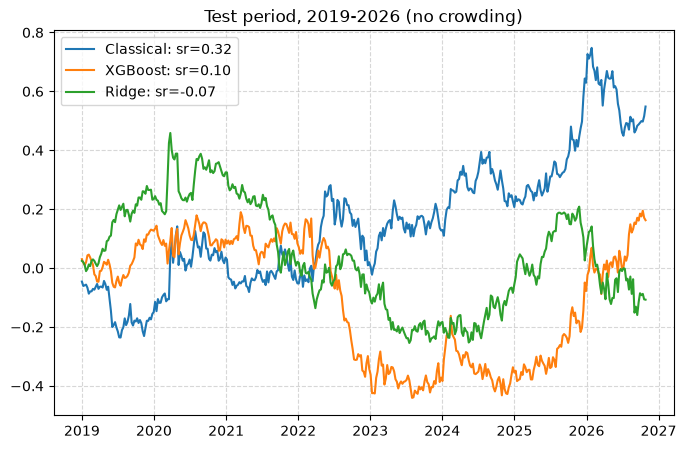

In [14]:
strategies = {"Classical": w.loc[START_ML:features.index[-1]]}
backtests = {}

for name, method, params in (
    ("Ridge", "ridge", ridge_params),
    ("XGBoost", "xgboost", xgb_params),
):
    backtest = Backtester(
        RankModel(method, params), max_train_size=TRAIN_WEEKS,
        test_size=1, pred_lag=1, start_date=START_ML,
    )
    backtest.train(features, target, ret)
    backtests[name] = backtest
    strategies[name] = backtest.h_.loc[START_ML:features.index[-1], ETFS]

common = strategies["XGBoost"].index
strategies = {name: h.loc[common] for name, h in strategies.items()}
pnls_ml = {name: pnl(h) for name, h in strategies.items()}

periods = {
    "Validation": slice(START_ML, VALID_END),
    "Test": slice(TEST_START, None),
}
performance = pd.DataFrame({
    period: {name: sr(returns.loc[dates]) for name, returns in pnls_ml.items()}
    for period, dates in periods.items()
})
display(performance.round(3))

line({f"{name}: sr={sr(value.loc[TEST_START:]):.2f}": value.loc[TEST_START:]
      for name, value in pnls_ml.items()},
     cumsum=True, legend_sharpe_ratio=False, loc="best",
     title="Test period, 2019-2026 (no crowding)")

To account for transaction costs, we consider a cost of 5 basis points (0.05%) on the amount traded at each portfolio rebalancing. Net returns are computed by subtracting these costs from gross portfolio returns:


$R_{t+1}^{net} = R_{t+1} - c \sum_{i=1}^{12} |w_{i,t} - w_{i,t-1}|, \qquad c = 0.0005$


In [15]:
pnls_net = {}
for name, h in strategies.items():
    turnover = h.diff().fillna(h).abs().sum(axis=1)
    turnover.index = turnover.index + pd.Timedelta(weeks=1)
    pnls_net[name] = pnls_ml[name] - COST_BPS / 10000 * turnover.reindex(pnls_ml[name].index).fillna(0)

pd.DataFrame({
    name: {
        "Test gross Sharpe": sr(pnls_ml[name].loc[TEST_START:]),
        "Test net Sharpe": sr(pnls_net[name].loc[TEST_START:]),
    }
    for name in strategies
}).T.round(3)

,Test gross Sharpe,Test net Sharpe
Classical,0.318,0.286
Ridge,-0.067,-0.212
XGBoost,0.101,-0.103


### 4.5 Forecast diagnostics

On the test weeks, we report the error of the forecasts (RMSE) and their Rank IC, the average weekly rank correlation between forecasts and realised returns.

In [16]:
diagnostics = {}
for name, backtest in backtests.items():
    dates = strategies[name].loc[TEST_START:].index
    forecast = pd.DataFrame(
        np.vstack([model.forecast(features.loc[[date]].to_numpy())
                   for date, model in zip(backtest.h_.index, backtest.estimators_)]),
        index=backtest.h_.index, columns=ETFS,
    ).loc[dates]
    actual = target.loc[dates]
    diagnostics[name] = {
        "RMSE": np.sqrt(((forecast - actual) ** 2).stack().mean()),
        "Rank IC": forecast.corrwith(actual, axis=1, method="spearman").mean(),
    }
    assert (strategies[name].gt(0).sum(axis=1) == N_LEG).all()
    assert (strategies[name].lt(0).sum(axis=1) == N_LEG).all()
    assert np.allclose(strategies[name].sum(axis=1), 0)

pd.DataFrame(diagnostics).T.round(4)

,RMSE,Rank IC
Ridge,0.0483,-0.0173
XGBoost,0.0504,0.0043


### 4.6 Adding the crowding indicator

As in Section 2, we compute the crowding of each ML portfolio with the positions measured on the Tuesday of the decision (lag 0, not executable), and hold the portfolio only when this crowding is below its average over the previous 156 weeks:

$$
C^{ML}_t = \frac{1}{2}\sum_{i=1}^{12} w^{ML}_{i,t}\, C_{i,t},
\qquad
\bar C^{ML}_t = \frac{1}{156}\sum_{k=1}^{156} C^{ML}_{t-k},
\qquad
e^{ML}_t = \mathbb{1}_{\{C^{ML}_t < \bar C^{ML}_t\}},
$$

$$
R^{ML}_{t+1} = \sum_{i=1}^{12} w^{ML}_{i,t}\, r_{i,t+1},
\qquad
R^{ML,LOW}_{t+1} = e^{ML}_t\, R^{ML}_{t+1}.
$$

The ML portfolios start in November 2015, so the 156-week threshold is available from November 2018, before the test starts. All strategies are compared on the test weeks, from 2019 onward.

The first table reports the performance of each strategy over the test weeks; the second compares Sharpe ratios before and after transaction costs. Costs matter more for the ML portfolios than for momentum: over the test weeks, they hold positions for 2.5 to 3.6 weeks on average, against 14.9 for momentum, as Chapter 15 notes for its Ridge strategy. The indicator adds trades too, since each switch sells or buys back the whole portfolio. The charts show returns before costs.

In [17]:
crowded = {}
for name in ("Ridge", "XGBoost"):
    _, _, low_ml = regime(crowding, weights=strategies[name])
    crowded[f"{name}, low crowding"] = strategies[name].loc[low_ml.index].mul(low_ml.astype(float), axis=0)
book_ml = {**strategies, **crowded}


def net_pnl(h):
    turnover = h.diff().fillna(h).abs().sum(axis=1)
    turnover.index = turnover.index + pd.Timedelta(weeks=1)
    return pnl(h) - COST_BPS / 10000 * turnover.reindex(pnl(h).index).fillna(0)


test_dates = pnls_ml["XGBoost"].loc[TEST_START:].index - pd.Timedelta(weeks=1)
display(report({name: h.loc[test_dates] for name, h in book_ml.items()}))

pd.DataFrame({
    name: {"Test gross Sharpe": sr(pnl(h).loc[TEST_START:]), "Test net Sharpe": sr(net_pnl(h).loc[TEST_START:])}
    for name, h in book_ml.items()
}).T.round(2)

,Sharpe,return (%/yr),vol (%/yr),max drawdown (%),weeks invested (%),holding period (weeks)
Classical,0.32,6.97,21.96,-30.42,100.00,14.87
Ridge,-0.07,-1.36,20.25,-71.30,100.00,3.56
XGBoost,0.10,2.07,20.49,-63.07,100.00,2.50
"Ridge, low crowding",-0.23,-2.86,12.38,-41.17,44.74,1.83
"XGBoost, low crowding",0.13,1.78,13.82,-30.89,47.19,1.51


,Test gross Sharpe,Test net Sharpe
Classical,0.32,0.29
Ridge,-0.07,-0.21
XGBoost,0.10,-0.10
"Ridge, low crowding",-0.23,-0.44
"XGBoost, low crowding",0.13,-0.11


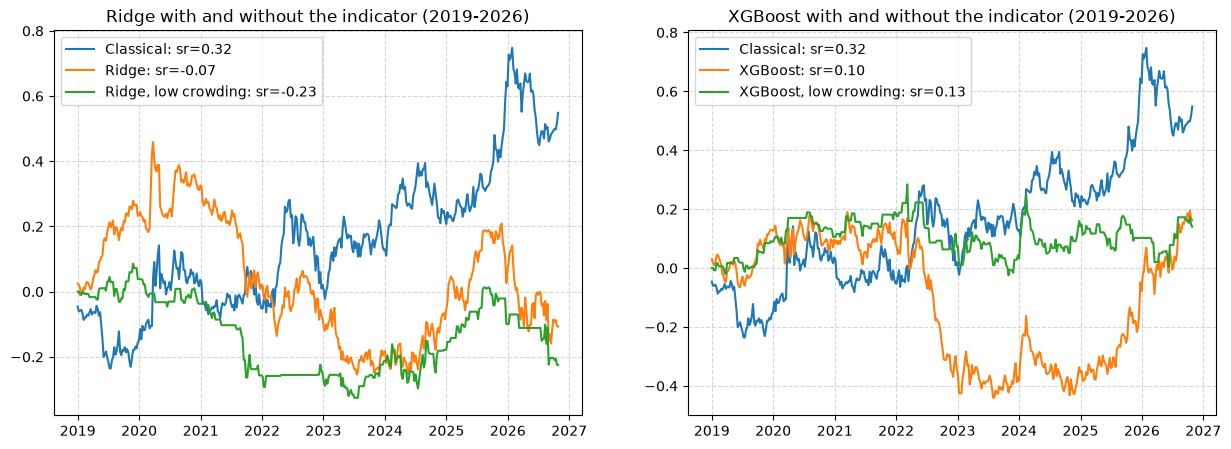

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, name in zip(axes, ("Ridge", "XGBoost")):
    shown = ("Classical", name, f"{name}, low crowding")
    line({f"{k}: sr={sr(pnl(book_ml[k]).loc[TEST_START:]):.2f}": pnl(book_ml[k]).loc[TEST_START:] for k in shown},
         cumsum=True, legend_sharpe_ratio=False, loc="best", ax=ax,
         title=f"{name} with and without the indicator (2019-2026)")

### 4.7 Does the indicator improve the strategy?

As in Chapter 12 of the course (style analysis), we regress the weekly returns of each filtered strategy on those of the same strategy without the indicator, over the test weeks:

$$
R^{ML,LOW}_{t} = \alpha + \beta\, R^{ML}_{t} + \varepsilon_t.
$$

$\beta$ measures the sensitivity of the filtered returns to the unfiltered ones, and $\alpha$ the average return the filtered strategy earns beyond this exposure. If the indicator chose its weeks at random, $\beta$ would equal the share of weeks invested and $\alpha$ would be zero: $\alpha$ measures whether the indicator keeps the good weeks better than chance. We reject $\alpha = 0$ when $|t| > 1.96$, where $t$ is $\hat\alpha$ divided by its Newey-West standard error, with 13 lags as in the paper, which allows for autocorrelation and changing variance of the residuals.

In [19]:
def filter_regression(name):
    filtered = pnl(book_ml[f"{name}, low crowding"]).loc[TEST_START:]
    unfiltered = pnl(book_ml[name]).loc[TEST_START:].rename(name)
    fit = sm.OLS(filtered, sm.add_constant(unfiltered)).fit(cov_type="HAC", cov_kwds={"maxlags": 13})
    return {
        "alpha (%/yr)": fit.params["const"] * 5200,
        "t(alpha)": fit.tvalues["const"],
        "beta": fit.params[name],
        "R2": fit.rsquared,
    }


pd.DataFrame({name: filter_regression(name) for name in ("Ridge", "XGBoost")}).T.round(2)

,alpha (%/yr),t(alpha),beta,R2
Ridge,-2.35,-0.85,0.37,0.37
XGBoost,0.84,0.25,0.45,0.45


## 5. Conclusion

We tested whether a crowding indicator, built from CFTC positions as in Kang, Rouwenhorst and Tang (2021), improves a commodity ETF strategy.

**Findings.** On momentum, we find the shape of the paper's result: returns are higher after low crowding. But this gap relies on positions measured on the day of the decision and published three days later; with published positions, the low-crowding strategy does no better than classical momentum. On the two machine-learning strategies, we use the same timing as in Part 1, the one under which the indicator worked best for momentum, and returns before costs. We detect no significant alpha from the indicator, and after costs it does not raise the Sharpe ratio either.

**What may drive these results.** Our sample is short: about 11 years for momentum and 8 years of test for the machine-learning strategies, so Sharpe ratios are measured with large errors. Commodity momentum itself was weak over this period: the paper's appendix reports negative momentum returns over 2015-2019 (Table A1), and its introduction cites low commodity momentum returns over the past decade. Our 12 ETFs cover fewer markets than the paper's 26 futures, with their own fees and roll schedules, and transaction costs are a simple assumption (5 basis points per unit traded, no borrowing cost). Finally, we saw test results while developing the models, so the test years are not fully independent of our choices, although the final hyperparameter search uses only the years before 2019. This may make the machine-learning results optimistic; the crowding rule itself is taken from the paper.

**Further work.** Crowding could be estimated before the CFTC publication, to obtain a signal available on the day of the decision; whether this estimate keeps the paper's result would have to be tested. Trading more slowly, as with the cost-aware portfolios of Chapter 15, would reduce the costs of the machine-learning strategies. Finally, the paper's 26 futures markets since 1993 and its other factors (value and carry) would give longer and broader tests.

## Statement of contributions

**Authors.** We first spent three hours agreeing on the direction, the hypotheses and the split of the work. We then reviewed and critiqued each other's contributions, and changed the plan, the models and the features several times as we went, based on the results and on our joint feedback. As a result, each of us had to understand and master the whole project.

**AI.** We used AI assistants (Claude and ChatGPT) to:
- critique our first plan (models and features), then our choices step by step;
- explore new ideas (models, features, tests), although the best ideas often came from us, after reading each other's work;
- clarify the modelling, as a private tutor would: for us, so that we knew exactly what we test and how we test it, and for the AI, so that it received precise instructions;
- go through all the course notebooks and functions, so that we reuse the course code rather than rewrite it, and compare strategies with the same tools as the course;
- write code from these precise instructions;
- check the code: question outlying values and look for errors (for example, our first version rebalanced the portfolio monthly instead of weekly, which left long periods without positions and gave a very low Sharpe ratio; the AI spotted it immediately);
- help critique the final results.